# Прилавок: прогноз недельных продаж дарксторов

## Задача

«Прилавок» — сеть из 45 дарксторов быстрой доставки продуктов, работает с 2023 года. Закупки планируются вручную по оценкам аналитиков, из-за этого возникают:
- дефицит в пиковые периоды (недополучение 3–5% выручки);
- избыточные запасы и списания скоропортящихся товаров (2–3% выручки);
- 15–20 часов ручной работы аналитиков в неделю.

**Цель** — автоматический прогноз недельных продаж для каждой пары «даркстор–отдел». Модель CatBoost обучается в этом ноутбуке, а еженедельный батч-инференс выполняет DAG в Airflow (`dags/`): каждое воскресенье вечером, чтобы к понедельнику прогнозы были в системе планирования закупок.

## Данные

Исторические продажи за февраль 2023 — октябрь 2025 в PostgreSQL:

- `sales` — недельные продажи: `store`, `dept`, `date` (начало недели), `weekly_sales` (целевая переменная, руб.), `is_holiday`;
- `stores` — тип (A, B, C) и размер даркстора;
- `features` — внешние факторы: температура, цена топлива, промо `factor1–5`, CPI, безработица;
- `plan` — недели для прогноза (ноябрь 2025 — июль 2026), используется в DAG.

## План

1. Первичный анализ и очистка данных.
2. Предобработка и создание признаков.
3. Мониторинг стабильности признаков (PSI).
4. Обучение модели CatBoost и оценка качества.

In [1]:
import os
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import psycopg2
from dotenv import load_dotenv

import warnings
warnings.filterwarnings("ignore")

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
RANDOM_STATE = 42

### Шаг 1. Первичный анализ данных

In [3]:
# Данные берутся из CSV в папке data/, если они там есть,
# иначе — из PostgreSQL. Параметры подключения — в файле .env (см. .env.example).
load_dotenv()
DATA = Path('data')

In [4]:
if (DATA / 'sales.csv').exists():
    sales = pd.read_csv(DATA / 'sales.csv', parse_dates=['date'])
    stores = pd.read_csv(DATA / 'stores.csv')
    features = pd.read_csv(DATA / 'features.csv', parse_dates=['date'])
else:
    conn = psycopg2.connect(
        host=os.getenv('DB_HOST'),
        port=os.getenv('DB_PORT'),
        dbname=os.getenv('DB_NAME'),
        user=os.getenv('DB_USER'),
        password=os.getenv('DB_PASSWORD'),
    )
    sales = pd.read_sql_query('SELECT * FROM sales', conn, parse_dates=['date'])
    stores = pd.read_sql_query('SELECT * FROM stores', conn)
    features = pd.read_sql_query('SELECT * FROM features', conn, parse_dates=['date'])
    conn.close()

In [5]:
tables = [sales, stores, features]

In [6]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   store         421570 non-null  int64         
 1   dept          421570 non-null  int64         
 2   date          421570 non-null  datetime64[us]
 3   weekly_sales  421570 non-null  float64       
 4   is_holiday    421570 non-null  bool          
dtypes: bool(1), datetime64[us](1), float64(1), int64(2)
memory usage: 13.3 MB


In [7]:
stores.info()

<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   store   45 non-null     int64
 1   type    45 non-null     str  
 2   size    45 non-null     int64
dtypes: int64(2), str(1)
memory usage: 1.2 KB


In [8]:
features.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 12 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   store         421570 non-null  int64         
 1   dept          421570 non-null  int64         
 2   date          421570 non-null  datetime64[us]
 3   temperature   421570 non-null  float64       
 4   fuel_price    421570 non-null  float64       
 5   factor1       421570 non-null  float64       
 6   factor2       111248 non-null  float64       
 7   factor3       137091 non-null  float64       
 8   factor4       134967 non-null  float64       
 9   factor5       151432 non-null  float64       
 10  cpi           421570 non-null  float64       
 11  unemployment  421570 non-null  float64       
dtypes: datetime64[us](1), float64(9), int64(2)
memory usage: 38.6 MB


In [9]:
for name, t in [('sales', sales), ('features', features)]:
    print(f"\n{name}: {t['date'].min().date()} — {t['date'].max().date()}")


sales: 2023-02-05 — 2025-10-26

features: 2023-02-05 — 2025-10-26


In [10]:
for name, t in [('sales', sales), ('stores', stores), ('features', features)]:
    print(f'\n=== {name} ===')
    print('полных дублей:', t.duplicated().sum())
    na = t.isna().mean()
    print(na[na > 0].round(3).to_string() if na.any() else 'пропусков нет')

factor_cols = ['factor1', 'factor2', 'factor3', 'factor4', 'factor5']
print('\n доля пропусков factor по кварталам:')
print(features.groupby(features['date'].dt.to_period('Q'))[factor_cols]
      .apply(lambda x: x.isna().mean()).round(2))

g = sales.groupby(['store', 'dept'])['date']
gaps = (g.max() - g.min()).dt.days // 7 + 1 - g.count()
print('\nпар store-dept:', len(gaps),
      '| с пропущенными неделями:', (gaps > 0).sum(),
      '| всего пропущенных недель:', gaps.sum())


=== sales ===
полных дублей: 0
пропусков нет

=== stores ===
полных дублей: 0
пропусков нет

=== features ===


полных дублей: 0
factor2    0.736
factor3    0.675
factor4    0.680
factor5    0.641

 доля пропусков factor по кварталам:


        factor1  factor2  factor3  factor4  factor5
date                                               
2023Q1      0.0     1.00     1.00     1.00     1.00
2023Q2      0.0     1.00     1.00     1.00     1.00
2023Q3      0.0     1.00     1.00     1.00     1.00
2023Q4      0.0     1.00     1.00     1.00     1.00
2024Q1      0.0     1.00     1.00     1.00     1.00
2024Q2      0.0     1.00     1.00     1.00     1.00
2024Q3      0.0     1.00     1.00     1.00     1.00
2024Q4      0.0     0.48     0.40     0.46     0.38
2025Q1      0.0     0.02     0.12     0.10     0.00
2025Q2      0.0     0.46     0.14     0.11     0.00
2025Q3      0.0     0.23     0.07     0.09     0.00
2025Q4      0.0     0.75     0.09     0.15     0.00



пар store-dept: 3331 | с пропущенными неделями: 605 | всего пропущенных недель: 27667


In [11]:
sales = sales.drop_duplicates()
stores = stores.drop_duplicates()
features = features.drop_duplicates()

features[factor_cols] = features[factor_cols].fillna(features[factor_cols].mean())

print('пропусков после заполнения:', features.isna().sum().sum())

пропусков после заполнения: 0


**Вывод.** Дубликатов нет. Пропуски только в `factor2–5` (64–74%) и структурные:
до 2024Q3 эти данные не собирались, далее заполнены частично. Заполнили средним
по рекомендации шаблона; ожидаем дрейф этих признаков на шаге PSI. В `sales`
605 пар «даркстор–отдел» имеют пропущенные недели (27 667 недель всего),
поэтому лаговые признаки строятся по дате, а не по позиции строки.

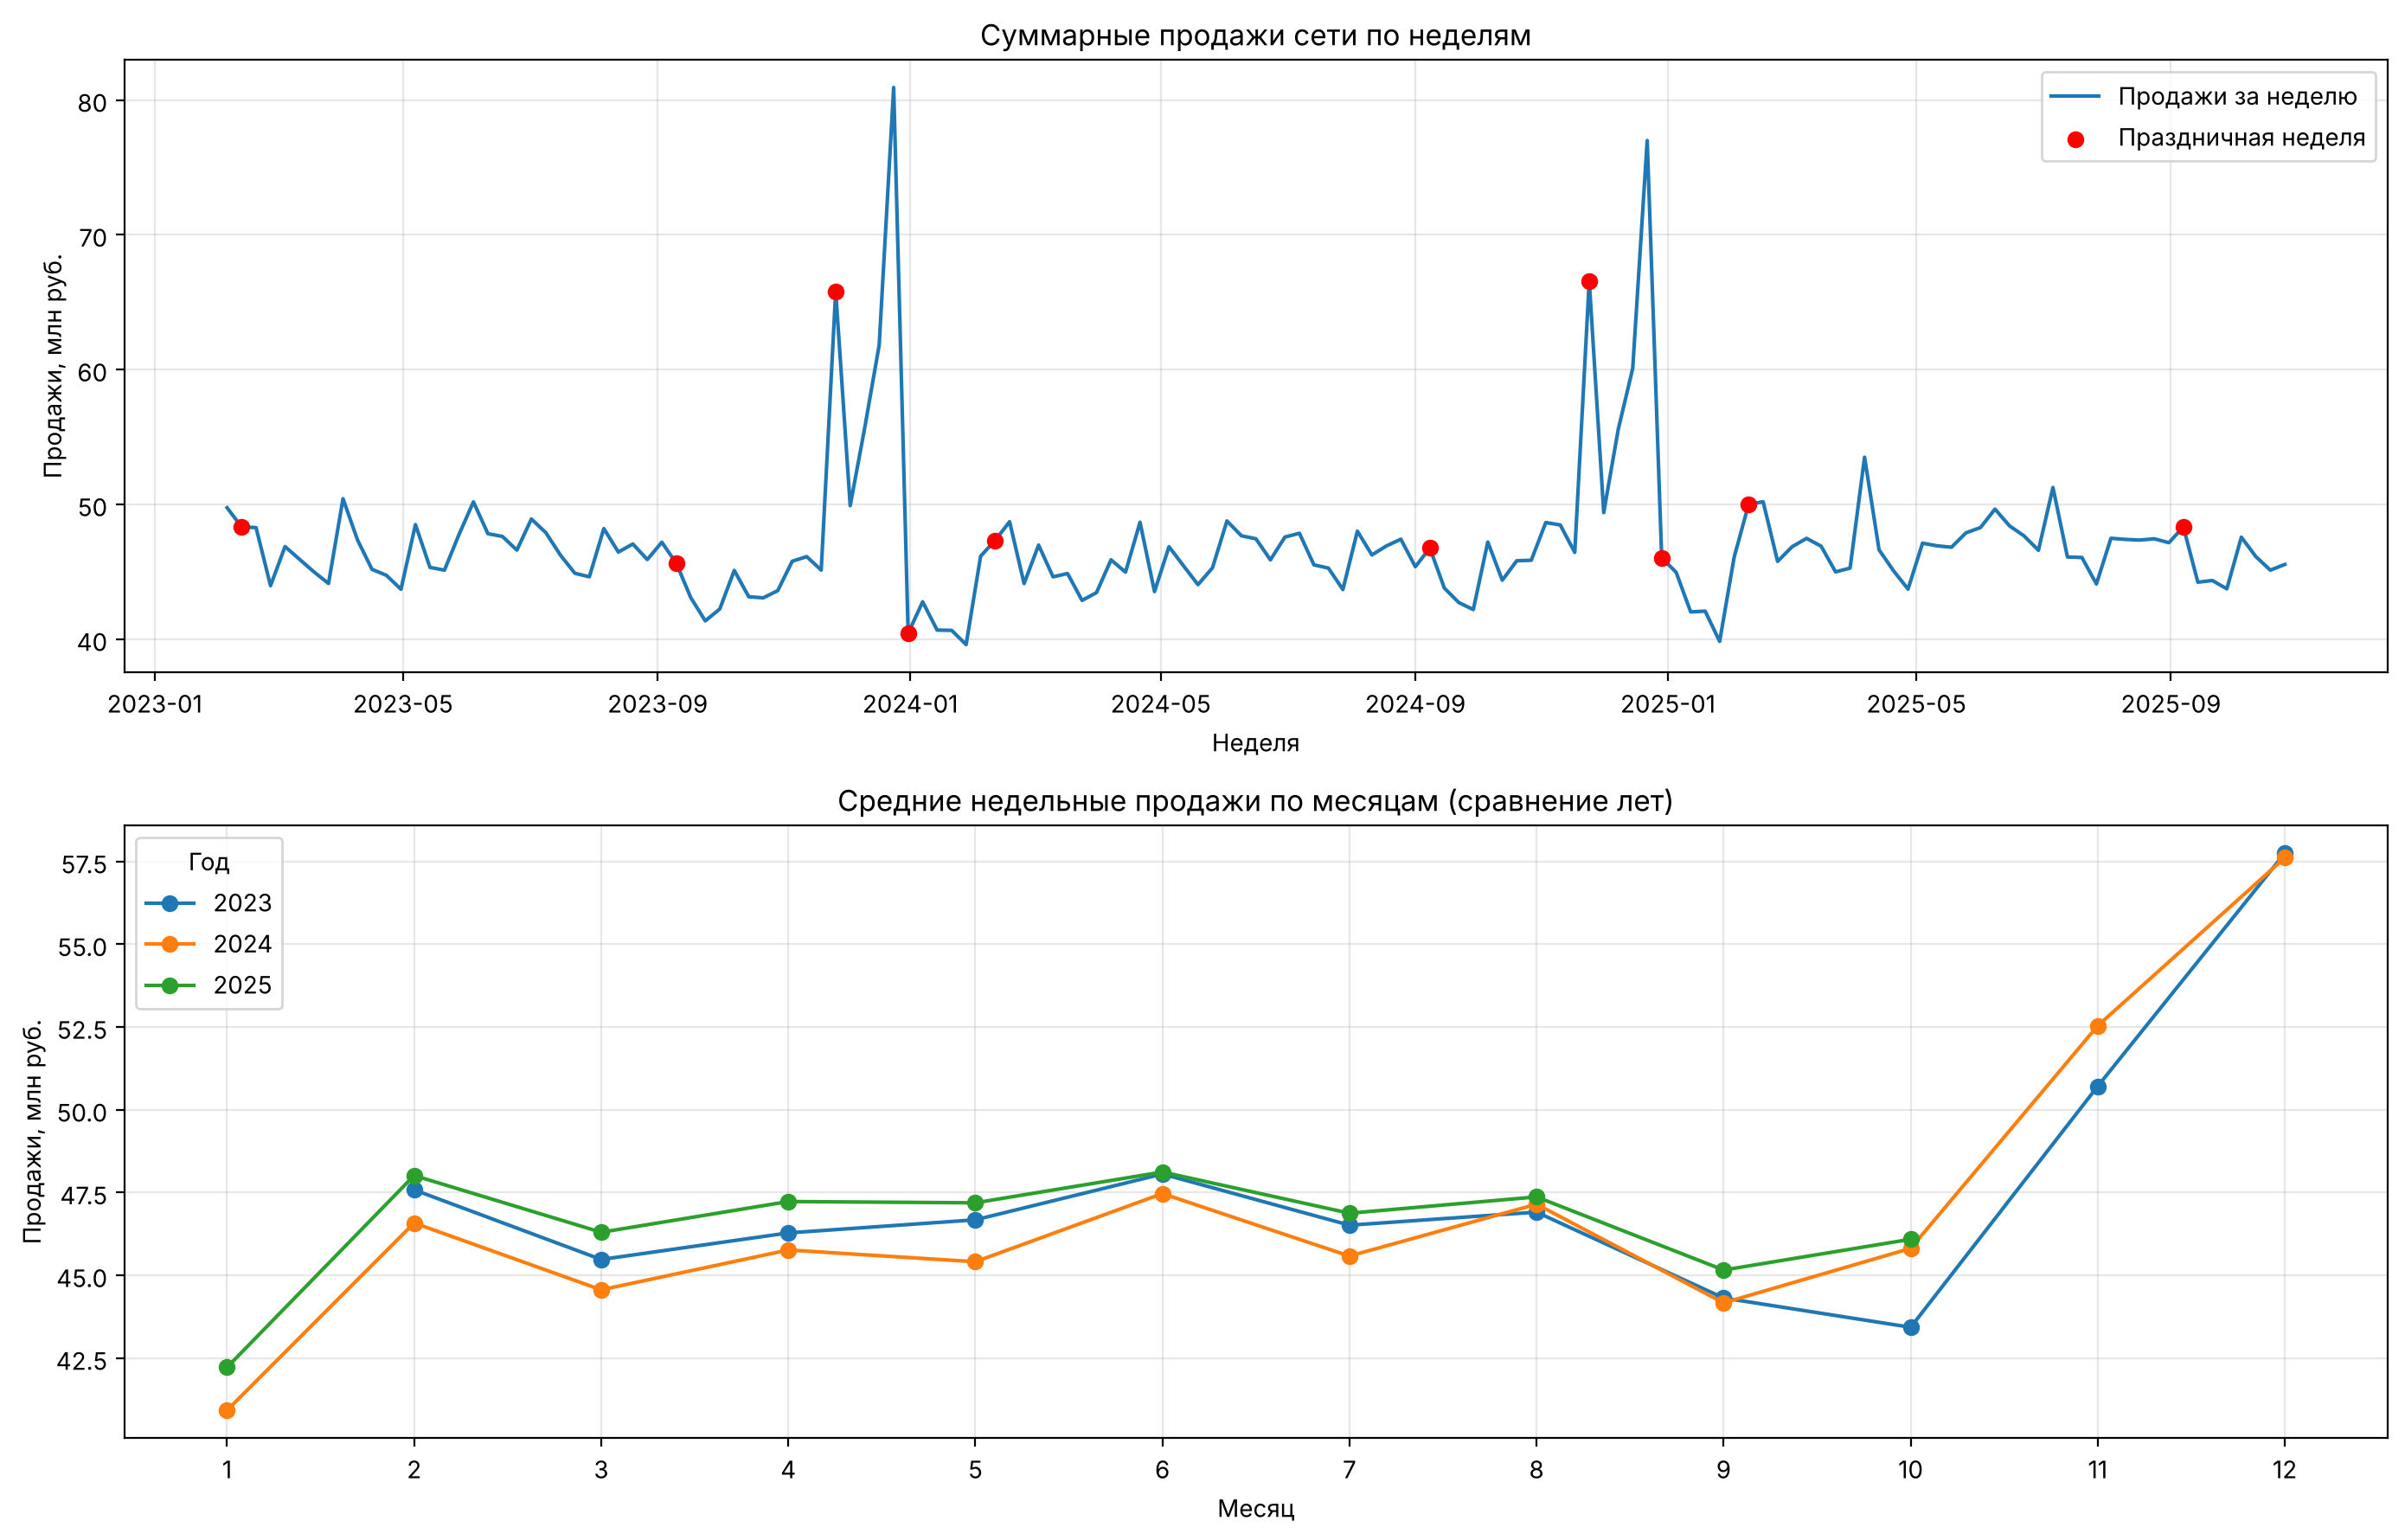

         date        total  holiday
46 2023-12-24  80931415.60    False
98 2024-12-22  76998241.31    False
94 2024-11-24  66593605.26     True
42 2023-11-26  65821003.24     True
45 2023-12-17  61820799.85    False
          date        total  holiday
51  2024-01-28  39599852.99    False
103 2025-01-26  39834974.67    False
47  2023-12-31  40432519.00     True
50  2024-01-21  40654648.03    False
49  2024-01-14  40673678.04    False


In [12]:
weekly = (sales.groupby('date')
          .agg(total=('weekly_sales', 'sum'), holiday=('is_holiday', 'max'))
          .reset_index())

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(weekly['date'], weekly['total'] / 1e6, label='Продажи за неделю')
hol = weekly[weekly['holiday']]
axes[0].scatter(hol['date'], hol['total'] / 1e6, color='red', zorder=3, label='Праздничная неделя')
axes[0].set(title='Суммарные продажи сети по неделям', xlabel='Неделя', ylabel='Продажи, млн руб.')
axes[0].legend()
axes[0].grid(alpha=0.3)

monthly = (weekly.assign(year=weekly['date'].dt.year, month=weekly['date'].dt.month)
           .groupby(['year', 'month'])['total'].mean()
           .unstack(0) / 1e6)
monthly.plot(ax=axes[1], marker='o')
axes[1].set(title='Средние недельные продажи по месяцам (сравнение лет)',
            xlabel='Месяц', ylabel='Продажи, млн руб.')
axes[1].set_xticks(range(1, 13))
axes[1].legend(title='Год')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(weekly.nlargest(5, 'total'))
print(weekly.nsmallest(5, 'total'))

**Вывод.** Выражена устойчивая годовая сезонность: формы кривых 2023–2025 почти
совпадают, общего тренда нет (уровень 45–48 млн руб./нед.). Пики — неделя
с праздником в конце ноября и две недели перед Новым годом (17 и 24 декабря),
причём последние не отмечены флагом `is_holiday`; праздничная неделя 31 декабря,
наоборот, одна из самых слабых. Минимум — январь. Отдельный всплеск в апреле 2025.
Следствия: одного `is_holiday` недостаточно, добавляем номер недели в году;
валидационный период (сен–окт 2025) не содержит пиков, поэтому метрики на нём
могут быть оптимистичнее реальной ошибки в высокий сезон.

In [13]:
df = (sales
      .merge(stores, on='store', how='left', validate='many_to_one')
      .merge(features, on=['store', 'dept', 'date'], how='left', validate='one_to_one'))

print(df.shape)
print('пропусков после объединения:', df.isna().sum().sum())
df.head()

(421570, 16)
пропусков после объединения: 0


,store,dept,date,weekly_sales,is_holiday,type,size,temperature,fuel_price,factor1,factor2,factor3,factor4,factor5,cpi,unemployment
0,1,1,2023-02-05,24924.50,False,A,151315,42.31,2.572,7028.8,3334.628621,1439.421384,3383.168256,4628.975079,211.096358,8.106
1,29,5,2023-02-05,15552.08,False,B,93638,24.36,2.788,7028.8,3334.628621,1439.421384,3383.168256,4628.975079,131.527903,10.064
2,29,6,2023-02-05,3200.22,False,B,93638,24.36,2.788,7028.8,3334.628621,1439.421384,3383.168256,4628.975079,131.527903,10.064
3,29,7,2023-02-05,10820.05,False,B,93638,24.36,2.788,7028.8,3334.628621,1439.421384,3383.168256,4628.975079,131.527903,10.064
4,29,8,2023-02-05,20055.64,False,B,93638,24.36,2.788,7028.8,3334.628621,1439.421384,3383.168256,4628.975079,131.527903,10.064


**Вывод.** Таблицы объединены по ключам `store` и `(store, dept, date)` со связью
один к одному: 421 570 строк, 16 столбцов, пропусков нет. Даты в `sales` и
`features` совпадают (все — воскресенья), сдвиг дат не потребовался.

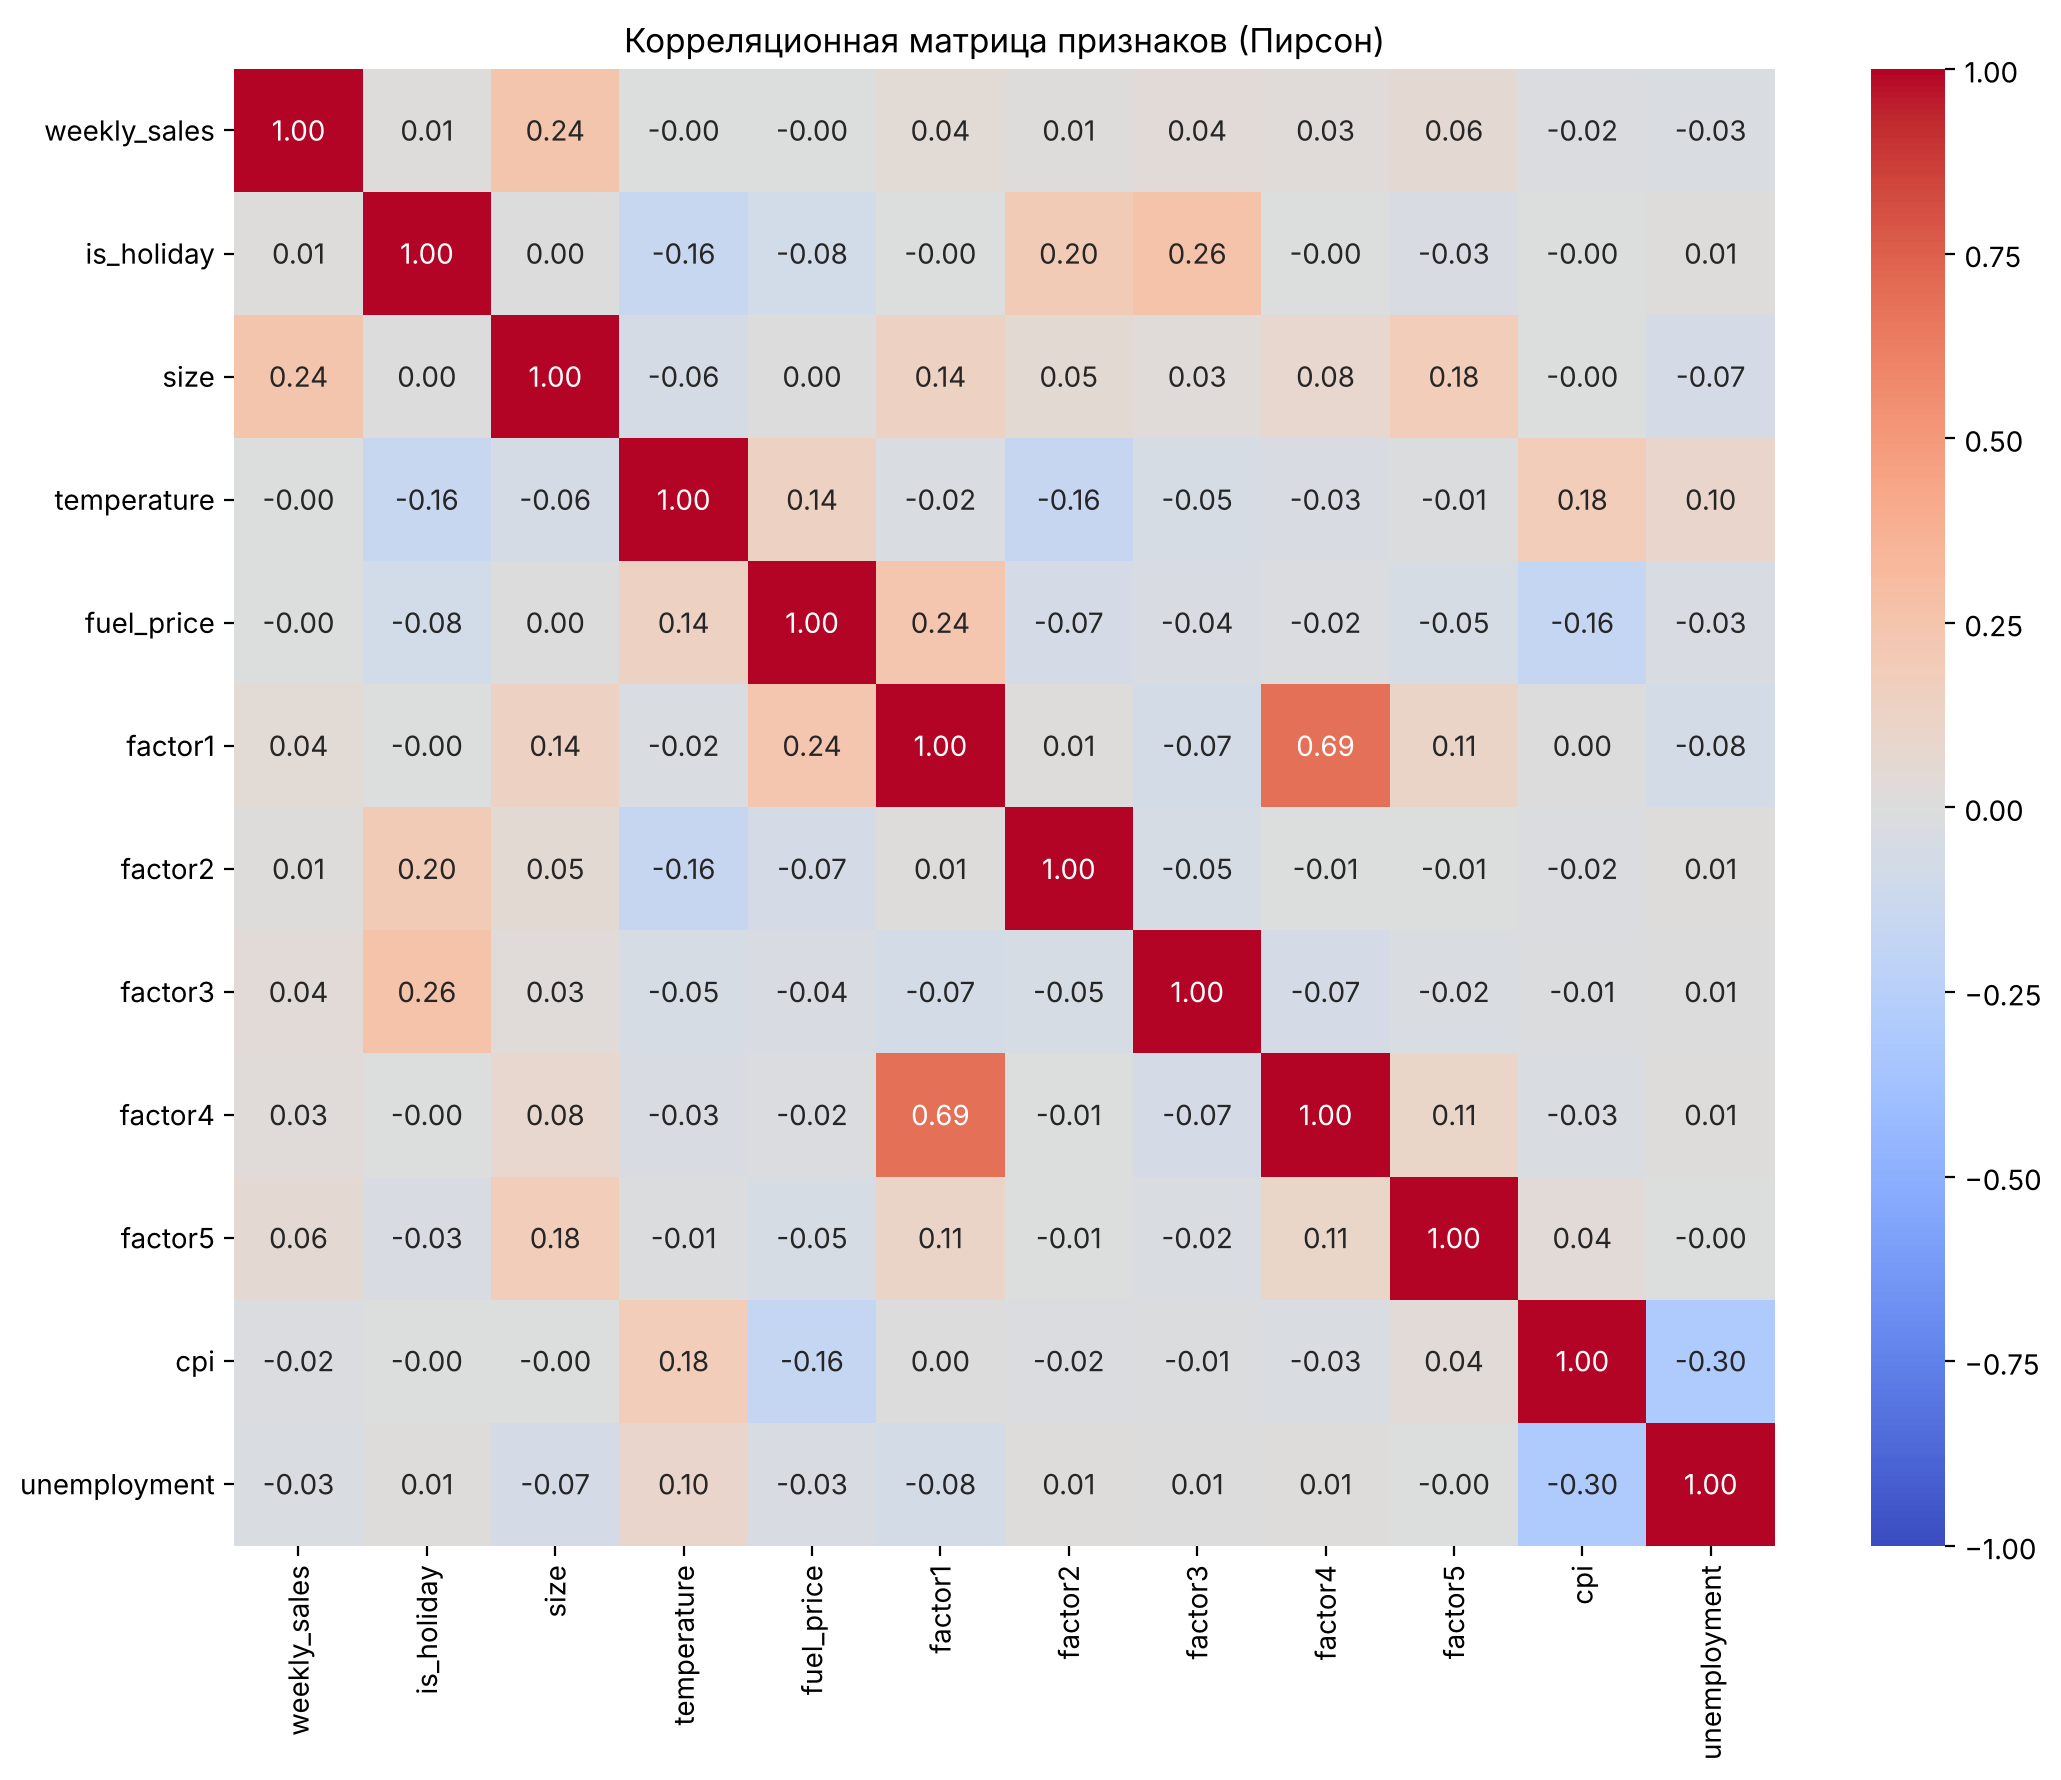

Корреляция с weekly_sales:
size            0.243828
factor5         0.055405
factor1         0.041175
factor3         0.036018
factor4         0.026984
unemployment   -0.025864
cpi            -0.020921
factor2         0.013121
is_holiday      0.012774
temperature    -0.002312
fuel_price     -0.000120
Name: weekly_sales, dtype: float64

Пары признаков с |r| > 0.7:
Series([], dtype: float64)


In [14]:
num_cols = ['weekly_sales', 'is_holiday', 'size', 'temperature', 'fuel_price',
            'factor1', 'factor2', 'factor3', 'factor4', 'factor5', 'cpi', 'unemployment']
corr = df[num_cols].astype(float).corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Корреляционная матрица признаков (Пирсон)')
plt.tight_layout()
plt.show()

print('Корреляция с weekly_sales:')
print(corr['weekly_sales'].drop('weekly_sales').sort_values(key=abs, ascending=False))

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print('\nПары признаков с |r| > 0.7:')
print(pairs[pairs.abs() > 0.7].sort_values(key=abs, ascending=False))

**Вывод.** Линейная связь с `weekly_sales` заметна только у `size` (r = 0.24):
крупные дарксторы продают больше. Внешние факторы коррелируют с продажами слабо
(|r| ≤ 0.06) — разброс продаж определяется прежде всего отделом, а не погодой или
макроэкономикой; нелинейные эффекты может уловить бустинг. Сильной
мультиколлинеарности нет: максимум |r| = 0.69 у пары `factor1`–`factor4`, ниже
порога 0.7, поэтому оба признака оставляем. `is_holiday` умеренно связан с
`factor2` и `factor3` (0.20–0.26) — часть промо, вероятно, приурочена к праздникам.

In [15]:
neg = df[df['weekly_sales'] < 0]
pos_sum = df.loc[df['weekly_sales'] > 0, 'weekly_sales'].sum()

print('отрицательных строк:', len(neg), f'({len(neg) / len(df):.2%})')
print('нулевых строк:', (df['weekly_sales'] == 0).sum())
print('сумма отрицательных, млн руб.:', round(neg['weekly_sales'].sum() / 1e6, 2),
      f"({abs(neg['weekly_sales'].sum()) / pos_sum:.4%} от суммы положительных)")

print('\nраспределение отрицательных значений:')
print(neg['weekly_sales'].describe().round(1))

print('\nтоп-10 отделов по числу отрицательных недель:')
print(neg['dept'].value_counts().head(10))

print('\nдоля отрицательных по типу даркстора:')
print(df.groupby('type')['weekly_sales'].apply(lambda s: (s < 0).mean()).round(4))

отрицательных строк: 1285 (0.30%)
нулевых строк: 73
сумма отрицательных, млн руб.: -0.09 (0.0013% от суммы положительных)

распределение отрицательных значений:
count    1285.0
mean      -68.6
std       231.7
min     -4988.9
25%       -41.0
50%       -13.2
75%        -4.9
max        -0.0
Name: weekly_sales, dtype: float64

топ-10 отделов по числу отрицательных недель:
dept
47    254
18    180
54    146
19     87
94     77
80     68
49     67
59     44
72     34
78     33
Name: count, dtype: int64

доля отрицательных по типу даркстора:
type
A    0.0023
B    0.0041
C    0.0029
Name: weekly_sales, dtype: float64


In [16]:
df['weekly_sales'] = df['weekly_sales'].clip(lower=0)
print('отрицательных после обработки:', (df['weekly_sales'] < 0).sum())

отрицательных после обработки: 0


**Вывод.** Отрицательные продажи — 1 285 строк (0.30%), в сумме 0.0013% объёма;
медиана −13 руб. Это возвраты, сосредоточенные в нескольких отделах (47, 18, 54),
а не ошибки учёта. Обнуляем их, а не удаляем: удаление добавило бы пропущенных
недель в ряды и ухудшило бы лаговые признаки, а отрицательный прогноз для
планирования закупок не имеет смысла.

In [17]:
thr = df['weekly_sales'].quantile(0.9999)
top = df[df['weekly_sales'] > thr].sort_values('weekly_sales', ascending=False)

print(f'порог 99.99%: {thr:,.0f} руб. | строк выше: {len(top)}')
print(top[['date', 'store', 'dept', 'type', 'size', 'weekly_sales', 'is_holiday']]
      .to_string(index=False))

print('\nпо месяцам:', top['date'].dt.month.value_counts().to_dict())
print('доля праздничных недель в топе:', round(top['is_holiday'].mean(), 2),
      '| во всех данных:', round(df['is_holiday'].mean(), 3))
print('по типам:', top['type'].value_counts().to_dict())
print('по отделам:', top['dept'].value_counts().to_dict())

apr = df[(df['date'] >= '2025-04-01') & (df['date'] < '2025-05-01')]
print('\nапрель 2025, продажи по неделям, млн:')
print((apr.groupby('date')['weekly_sales'].sum() / 1e6).round(1))

порог 99.99%: 283,660 руб. | строк выше: 43
      date  store  dept type   size  weekly_sales  is_holiday
2023-11-26     10    72    B 126512     693099.36        True
2024-11-24     35    72    B 103681     649770.18        True
2024-11-24     10    72    B 126512     630999.19        True
2023-11-26     35    72    B 103681     627962.93        True
2023-11-26     14    72    A 200898     474330.10        True
2023-11-26     20    72    A 203742     422306.25        True
2023-11-26     27    72    A 204184     420586.57        True
2023-12-24     10     7    B 126512     406988.63       False
2023-12-24     10    72    B 126512     404245.03       False
2023-11-26     22    72    B 119557     393705.20        True
2024-11-24     20    72    A 203742     392023.02        True
2024-11-24      4    72    A 205863     385051.04        True
2023-11-26      4    72    A 205863     381072.11        True
2024-11-24     14    72    A 200898     375948.31        True
2023-11-26     23    72   

**Вывод.** Выше 99.99% квантиля (283 660 руб.) — 43 строки. 72% из них —
праздничные недели (против 7% в среднем). Пики формируют два отдела: 72 —
в неделю праздника конца ноября, 7 — в предновогодние недели; одни и те же
крупные дарксторы типов A и B повторяют пики в 2023 и 2024 гг. Это реальный
сезонный спрос, а не ошибки, поэтому значения оставляем — именно эти пики модель
должна предсказывать. Всплеск апреля 2025 — одна неделя (6 апреля, 53.5 млн руб.),
распределён по многим отделам; причина в данных не идентифицируется, значение
сохраняем.

### Шаг 2. Предобработка признаков и feature engineering

In [18]:
def create_temporal_features(df) -> pd.DataFrame:
    """Календарные признаки из даты недели (date — воскресенье)."""
    df = df.copy()
    df['month'] = df['date'].dt.month
    df['quarter'] = df['date'].dt.quarter
    df['year'] = df['date'].dt.year
    df['week'] = df['date'].dt.isocalendar().week.astype(int)
    return df

df = create_temporal_features(df)

check_dates = ['2023-11-26', '2024-11-24', '2023-12-24', '2024-12-22']
print(df.loc[df['date'].isin(check_dates), ['date', 'month', 'quarter', 'year', 'week']]
      .drop_duplicates())

Empty DataFrame
Columns: [date, month, quarter, year, week]
Index: []


In [19]:
assert 'month' in df.columns, 'Месяц не создан!'
assert 'quarter' in df.columns, 'Квартал не создан!'
assert 'year' in df.columns, 'Год не создан!'

**Вывод.** Добавлены `month`, `quarter`, `year` и номер недели ISO `week`.
`week` выравнивает сезонные пики между годами (праздник конца ноября — неделя 47,
предновогодний пик — 51 в оба года). День недели не используется: все даты
в данных — воскресенья, признак был бы константой.

In [20]:
def create_avg_sales_feature(df):
    """Средняя и медиана продаж пары «даркстор–отдел» по всем неделям строго до текущей."""
    df = df.sort_values(['store', 'dept', 'date']).reset_index(drop=True)
    past = df.groupby(['store', 'dept'])['weekly_sales'].shift(1)
    grp = past.groupby([df['store'], df['dept']])
    df['avg_sales_before'] = grp.transform(lambda s: s.expanding().mean())
    df['median_sales_before'] = grp.transform(lambda s: s.expanding().median())
    return df

df = create_avg_sales_feature(df)

pair = df[(df['store'] == 1) & (df['dept'] == 1)]
row = pair.iloc[10]
manual = pair.loc[pair['date'] < row['date'], 'weekly_sales']
print('дата:', row['date'].date())
print('avg:   ', round(row['avg_sales_before'], 2), '| вручную:', round(manual.mean(), 2))
print('median:', round(row['median_sales_before'], 2), '| вручную:', round(manual.median(), 2))
print('\nNaN в avg_sales_before:', df['avg_sales_before'].isna().sum(),
      '| число пар:', df.groupby(['store', 'dept']).ngroups)

дата: 2023-04-16
avg:    32341.96 | вручную: 32341.96
median: 25576.86 | вручную: 25576.86

NaN в avg_sales_before: 3331 | число пар: 3331


In [21]:
assert 'avg_sales_before' in df.columns, 'Признак средних продаж не создан!'

**Вывод.** `avg_sales_before` и `median_sales_before` считаются по всем неделям
пары «даркстор–отдел» строго до текущей (сдвиг на одну строку + накопительное
окно); совпадение с ручным расчётом подтверждает отсутствие утечки. NaN — только
у первой недели каждой из 3 331 пары. Медиана добавлена как устойчивая к пикам
альтернатива среднему.

In [22]:
def create_lag_features(df):
    """Продажи той же пары ровно 1, 2, 4 и 52 недели назад — по дате, а не по позиции строки."""
    df = df.copy()
    base = df[['store', 'dept', 'date', 'weekly_sales']]
    for k in (1, 2, 4, 52):
        lag = (base.assign(date=base['date'] + pd.Timedelta(weeks=k))
                   .rename(columns={'weekly_sales': f'sales_{k}week_ago'}))
        df = df.merge(lag, on=['store', 'dept', 'date'], how='left')
    return df

df = create_lag_features(df)

lag_cols = ['sales_1week_ago', 'sales_2week_ago', 'sales_4week_ago', 'sales_52week_ago']
print('строк:', len(df))
print('NaN:', df[lag_cols].isna().sum().to_dict())

shift1 = df.groupby(['store', 'dept'])['weekly_sales'].shift(1)
print('строк, где shift(1) подставил бы не ту неделю:',
      (shift1.notna() & df['sales_1week_ago'].isna()).sum())

строк: 421570
NaN: {'sales_1week_ago': 8778, 'sales_2week_ago': 12246, 'sales_4week_ago': 18792, 'sales_52week_ago': 160029}
строк, где shift(1) подставил бы не ту неделю: 5447


In [23]:
assert 'sales_1week_ago' in df.columns, 'Признак sales_1week_ago не создан!'
assert 'sales_2week_ago' in df.columns, 'Признак sales_2week_ago не создан!'
assert 'sales_4week_ago' in df.columns, 'Признак sales_4week_ago не создан!'

**Вывод.** Лаги 1, 2 и 4 недели строятся по дате (`date − 7·k дней`), а не
через `shift`: в 605 парах есть пропущенные недели, и сдвиг по строкам в 5 447 случаях
подставил бы продажи более ранней недели вместо отсутствующей. Если нужной недели
нет, лаг — NaN; такие строки обрабатываются на шаге `dropna`.

Лаг 52 недели — продажи той же пары в ту же неделю год назад. Он передаёт годовую
сезонность и эффект конкретного праздника: `is_holiday` одинаково отмечает и
ноябрьский пик, и небольшие праздники, поэтому сам по себе их не различает.
Пропуск в этом лаге (первый год данных) не удаляется — CatBoost обрабатывает NaN.

In [24]:
def create_rolling_features(df):
    """Среднее продаж пары за 2 и 4 календарные недели строго до текущей."""
    df = df.sort_values(['store', 'dept', 'date']).reset_index(drop=True)
    for w in (2, 4):
        rolled = (df.groupby(['store', 'dept'])
                    .rolling(f'{7 * w}D', on='date', closed='left')['weekly_sales']
                    .mean())
        assert (rolled.index.get_level_values(0).to_numpy() == df['store'].to_numpy()).all()
        assert (rolled.index.get_level_values(1).to_numpy() == df['dept'].to_numpy()).all()
        df[f'mean_sales_{w}week'] = rolled.to_numpy()
    return df

df = create_rolling_features(df)

pair = df[(df['store'] == 1) & (df['dept'] == 1)]
row = pair.iloc[10]
win = pair.loc[(pair['date'] >= row['date'] - pd.Timedelta(weeks=4)) &
               (pair['date'] < row['date']), 'weekly_sales']
print('дата:', row['date'].date())
print('4 нед:', round(row['mean_sales_4week'], 2), '| вручную:', round(win.mean(), 2), '| недель в окне:', len(win))
print('\nNaN:', df[['mean_sales_2week', 'mean_sales_4week']].isna().sum().to_dict())

дата: 2023-04-16
4 нед: 37146.3 | вручную: 37146.3 | недель в окне: 4

NaN: {'mean_sales_2week': 6432, 'mean_sales_4week': 5053}


In [25]:
assert 'mean_sales_2week' in df.columns, 'Признак mean_sales_2week не создан!'
assert 'mean_sales_4week' in df.columns, 'Признак mean_sales_4week не создан!'

**Вывод.** Скользящие средние за 2 и 4 недели считаются по календарному окну
`[T − 7·w дней, T)`, текущая неделя в окно не входит. NaN (6 432 и 5 053) —
у первых недель пар и после длинных пропусков, где в окне нет ни одной недели.

In [26]:
# sales_52week_ago не участвует в dropna: годовая история есть только с 2024 года,
# а CatBoost умеет работать с пропусками
YEARLY_LAG = 'sales_52week_ago'

before = len(df)
df = df.dropna(subset=[c for c in df.columns if c != YEARLY_LAG]).reset_index(drop=True)

print(f'строк: {before} → {len(df)} (удалено {before - len(df)}, {(before - len(df)) / before:.2%})')
print('NaN после удаления:', df.drop(columns=YEARLY_LAG).isna().sum().sum())
print(f'доля пропусков в {YEARLY_LAG}: {df[YEARLY_LAG].isna().mean():.1%}')
print('даты:', df['date'].min().date(), '—', df['date'].max().date())
print('пар «даркстор–отдел» осталось:', df.groupby(['store', 'dept']).ngroups)

строк: 421570 → 398838 (удалено 22732, 5.39%)
NaN после удаления: 0
доля пропусков в sales_52week_ago: 35.4%
даты: 2023-03-05 — 2025-10-26
пар «даркстор–отдел» осталось: 3111


**Вывод.** Удалено 22 732 строки (5.39%) — первые 4 недели каждого ряда и недели
после пропусков, где нет лага в 4 недели. Данные начинаются с 2023-03-05.
Полностью выпали 220 пар «даркстор–отдел» с историей короче окна лагов.
Пропуски в `sales_52week_ago` (35.4% — в основном первый год данных) сохранены.

### Шаг 3. Мониторинг стабильности признаков

In [27]:
TARGET = 'weekly_sales'
SPLIT_DATE = pd.Timestamp('2025-09-01')

cat_features = ['store', 'dept', 'type']
num_features = ['size', 'is_holiday', 'temperature', 'fuel_price',
                'factor1', 'factor2', 'factor3', 'factor4', 'factor5', 'cpi', 'unemployment',
                'month', 'quarter', 'year', 'week',
                'avg_sales_before', 'median_sales_before',
                'sales_1week_ago', 'sales_2week_ago', 'sales_4week_ago', 'sales_52week_ago',
                'mean_sales_2week', 'mean_sales_4week']
feature_cols = cat_features + num_features

df['is_holiday'] = df['is_holiday'].astype(int)

train = df[df['date'] < SPLIT_DATE].reset_index(drop=True)
valid = df[df['date'] >= SPLIT_DATE].reset_index(drop=True)

for name, part in [('train', train), ('valid', valid)]:
    print(f"{name}: {part.shape[0]} строк ({part.shape[0] / len(df):.1%}), "
          f"{part['date'].min().date()} — {part['date'].max().date()}, "
          f"недель: {part['date'].nunique()}")

train: 375744 строк (94.2%), 2023-03-05 — 2025-08-31, недель: 131
valid: 23094 строк (5.8%), 2025-09-07 — 2025-10-26, недель: 8


In [28]:
EPS = 1e-6

def psi(expected, actual, bins=10, categorical=False):
    """PSI между train (expected) и valid (actual). Пропуски не учитываются."""
    expected, actual = expected.dropna(), actual.dropna()
    if not categorical:
        edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
        if len(edges) < 3:
            categorical = True
    if categorical:
        cats = pd.Index(expected.unique()).union(actual.unique())
        e = expected.value_counts(normalize=True).reindex(cats, fill_value=0).to_numpy()
        a = actual.value_counts(normalize=True).reindex(cats, fill_value=0).to_numpy()
    else:
        edges[0], edges[-1] = -np.inf, np.inf
        e = np.histogram(expected, edges)[0] / len(expected)
        a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, EPS, None), np.clip(a, EPS, None)
    return np.sum((a - e) * np.log(a / e))

rows = []
for col in feature_cols:
    is_cat = col in cat_features or train[col].nunique() <= 20
    rows.append({'feature': col, 'kind': 'cat' if is_cat else 'num',
                 'psi': psi(train[col], valid[col], categorical=is_cat)})

psi_df = pd.DataFrame(rows).sort_values('psi', ascending=False).reset_index(drop=True)
psi_df['status'] = pd.cut(psi_df['psi'], [-np.inf, 0.1, 0.2, np.inf], right=False,
                          labels=['стабилен', 'умеренный дрейф', 'значительный дрейф'])
print(psi_df.round(4).to_string())

                feature kind      psi              status
0                 month  cat  11.5446  значительный дрейф
1                  week  num  10.5565  значительный дрейф
2                  year  cat  10.3369  значительный дрейф
3               quarter  cat   6.9958  значительный дрейф
4            fuel_price  num   6.5788  значительный дрейф
5                   cpi  num   4.2176  значительный дрейф
6               factor5  num   2.9328  значительный дрейф
7               factor3  num   1.9724  значительный дрейф
8               factor1  num   1.9390  значительный дрейф
9               factor4  num   1.5223  значительный дрейф
10          temperature  num   1.4076  значительный дрейф
11              factor2  num   0.6585  значительный дрейф
12         unemployment  num   0.4266  значительный дрейф
13           is_holiday  cat   0.0499            стабилен
14                 dept  cat   0.0139            стабилен
15     sales_52week_ago  num   0.0027            стабилен
16      sales_

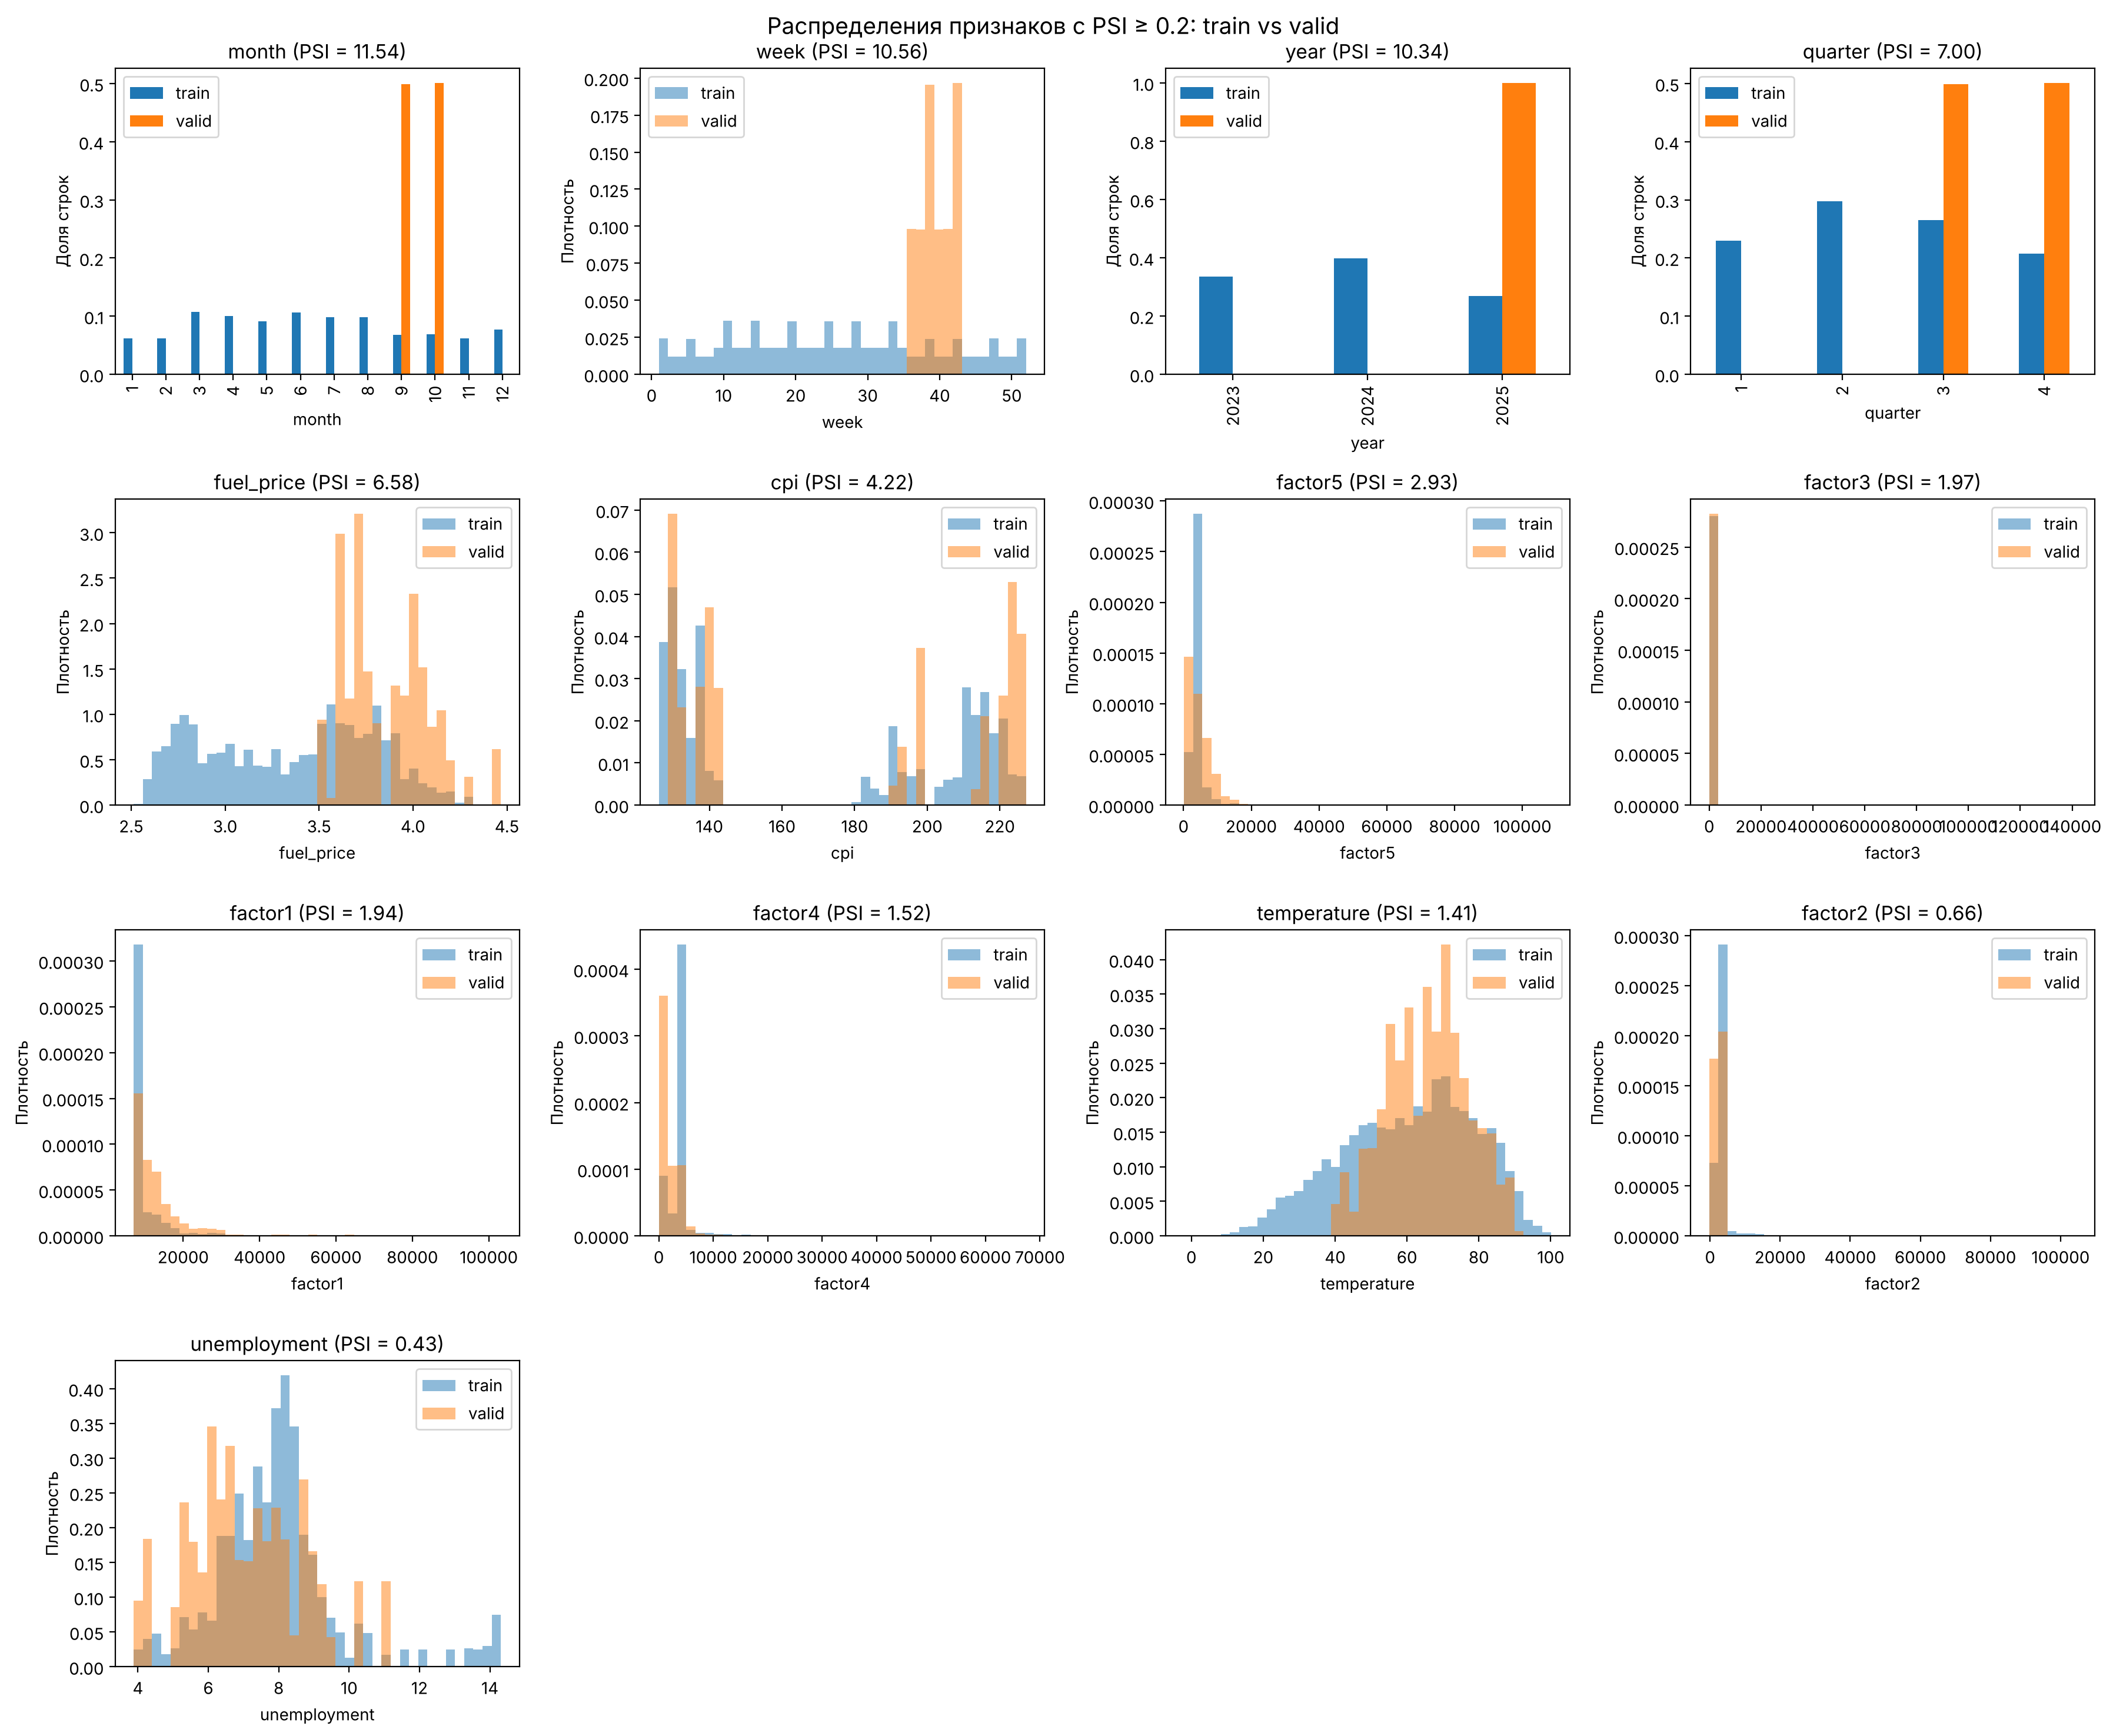

     feature  psi_весь_train  psi_сен–окт_прошлых_лет
       month          11.545                    0.000
        week          10.557                    1.293
        year          10.337                   26.938
     quarter           6.996                    0.000
  fuel_price           6.579                    7.664
         cpi           4.218                    4.999
     factor5           2.933                   21.752
     factor3           1.972                    9.335
     factor1           1.939                   12.935
     factor4           1.522                    8.918
 temperature           1.408                    0.059
     factor2           0.659                    4.146
unemployment           0.427                    0.705


In [29]:
drift = psi_df.loc[psi_df['psi'] >= 0.2, 'feature'].tolist()
psi_map = psi_df.set_index('feature')['psi']

fig, axes = plt.subplots(4, 4, figsize=(18, 15))
for ax, col in zip(axes.flat, drift):
    if train[col].nunique() <= 20:
        shares = pd.DataFrame({'train': train[col].value_counts(normalize=True),
                               'valid': valid[col].value_counts(normalize=True)}).fillna(0).sort_index()
        shares.plot.bar(ax=ax)
        ax.set_ylabel('Доля строк')
    else:
        bins = np.histogram_bin_edges(pd.concat([train[col], valid[col]]), bins=40)
        ax.hist(train[col], bins=bins, density=True, alpha=0.5, label='train')
        ax.hist(valid[col], bins=bins, density=True, alpha=0.5, label='valid')
        ax.set_ylabel('Плотность')
        ax.legend()
    ax.set_title(f'{col} (PSI = {psi_map[col]:.2f})')
    ax.set_xlabel(col)
for ax in axes.flat[len(drift):]:
    ax.axis('off')
plt.suptitle('Распределения признаков с PSI ≥ 0.2: train vs valid', fontsize=14)
plt.tight_layout()
plt.show()

same_season = train[train['month'].isin([9, 10])]
check = pd.DataFrame([{
    'feature': c,
    'psi_весь_train': psi_map[c],
    'psi_сен–окт_прошлых_лет': psi(same_season[c], valid[c], categorical=train[c].nunique() <= 20),
} for c in drift])
print(check.round(3).to_string(index=False))

**Интерпретация PSI.** Стабильны (PSI < 0.05) все признаки истории продаж, `store`,
`dept`, `type`, `size`, `is_holiday`. Значительный дрейф у 13 признаков, но причины
разные — проверили сравнением валидации с теми же месяцами (сен–окт) прошлых лет:
- `month`, `quarter`, `temperature`: PSI падает до ≈ 0 — дрейф вызван тем, что
  валидация покрывает только два месяца, а не изменением распределения;
  `week` — аналогично (1.29 за счёт несовпадения крайних недель периода);
- `year`: реальный сдвиг — в валидации только 2025, в плане появится 2026;
- `fuel_price`, `cpi`, `unemployment`: устойчивый макроэкономический тренд;
- `factor1–5`: смена режима данных — до 2024Q4 значения не собирались.
Кроме того, таблица `features` заканчивается 2025-10-26 и не покрывает период
плана, поэтому внешние факторы недоступны на инференсе.

In [30]:
# Удалите все признаки, у которых PSI ≥ 0.2
drop_features = ['year', 'month', 'quarter', 'week', 'fuel_price', 'cpi', 'unemployment', 'temperature',
                 'factor1', 'factor2', 'factor3', 'factor4', 'factor5']

feature_cols = [c for c in feature_cols if c not in drop_features]
num_features = [c for c in num_features if c not in drop_features]
train = train.drop(columns=drop_features)
valid = valid.drop(columns=drop_features)

print(len(feature_cols), 'признаков:', feature_cols)

13 признаков: ['store', 'dept', 'type', 'size', 'is_holiday', 'avg_sales_before', 'median_sales_before', 'sales_1week_ago', 'sales_2week_ago', 'sales_4week_ago', 'sales_52week_ago', 'mean_sales_2week', 'mean_sales_4week']


**Решение.** Удалены все признаки с PSI ≥ 0.2:
- `year` — на инференсе значения вне диапазона обучения, а деревья не экстраполируют;
- `month`, `quarter`, `week` — их высокий PSI вызван короткой валидацией (при сравнении
  с теми же месяцами прошлых лет PSI ≈ 0), но они и не нужны: сезонность и эффект
  конкретного праздника передаёт `sales_52week_ago`, у которого PSI 0.003;
- внешние факторы `fuel_price`, `cpi`, `unemployment`, `temperature`, `factor1–5` —
  реальный дрейф и отсутствие данных на период плана.

Итого 13 признаков.

### Шаг 4. Обучение модели CatBoost

In [31]:
%%time
X_train, y_train = train[feature_cols], train[TARGET]
X_valid, y_valid = valid[feature_cols], valid[TARGET]

# Число итераций подбираем ранней остановкой на отложенной выборке — последних 8 неделях train.
# Валидация в подборе не участвует и остаётся честной оценкой качества.
HOLDOUT_START = train['date'].max() - pd.Timedelta(weeks=7)
fit_part = train[train['date'] < HOLDOUT_START]
holdout = train[train['date'] >= HOLDOUT_START]
print(f"обучение: до {fit_part['date'].max().date()}, "
      f"holdout: {holdout['date'].min().date()} — {holdout['date'].max().date()}")

params = dict(learning_rate=0.1, depth=6, loss_function='RMSE', random_seed=RANDOM_STATE)

cb_es = CatBoostRegressor(iterations=2000, od_type='Iter', od_wait=100,
                          use_best_model=True, verbose=200, **params)
cb_es.fit(fit_part[feature_cols], fit_part[TARGET],
          cat_features=cat_features,
          eval_set=(holdout[feature_cols], holdout[TARGET]))
best_iter = cb_es.get_best_iteration() + 1
print('лучшее число итераций:', best_iter)

# Финальная модель обучается на всём train с найденным числом итераций
cb = CatBoostRegressor(iterations=best_iter, verbose=0, **params)
cb.fit(X_train, y_train, cat_features=cat_features)

обучение: до 2025-07-06, holdout: 2025-07-13 — 2025-08-31


0:	learn: 20967.9938005	test: 19981.1161082	best: 19981.1161082 (0)	total: 187ms	remaining: 6m 12s


200:	learn: 4292.6036521	test: 2568.8644999	best: 2568.7367583 (199)	total: 21.5s	remaining: 3m 12s


400:	learn: 3919.5742140	test: 2529.1211102	best: 2528.5739442 (361)	total: 43.6s	remaining: 2m 54s


600:	learn: 3687.8596256	test: 2522.3397739	best: 2516.9041219 (546)	total: 1m 6s	remaining: 2m 34s


Stopped by overfitting detector  (100 iterations wait)

bestTest = 2516.904122
bestIteration = 546

Shrink model to first 547 iterations.
лучшее число итераций: 547


CPU times: user 4min 16s, sys: 7.61 s, total: 4min 24s
Wall time: 2min 15s


CatBoostRegressor(depth=6, iterations=547, learning_rate=0.1, loss_function='RMSE', random_seed=42, verbose=0)

In [32]:
def regression_metrics(y_true, y_pred):
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': mean_squared_error(y_true, y_pred) ** 0.5,
            'R2': r2_score(y_true, y_pred)}

pred_train = cb.predict(X_train)
pred_valid = cb.predict(X_valid)

results = pd.DataFrame({
    'train': regression_metrics(y_train, pred_train),
    'valid': regression_metrics(y_valid, pred_valid),
    'valid_baseline_lag1': regression_metrics(y_valid, X_valid['sales_1week_ago']),
}).T
print(results.round(3))

print('\nотрицательных предсказаний на valid:', (pred_valid < 0).sum())
pred_valid_clipped = np.clip(pred_valid, 0, None)
print('valid после обрезки отрицательных до 0:')
print({k: round(v, 3) for k, v in regression_metrics(y_valid, pred_valid_clipped).items()})

# Отдельно праздничная неделя и обычные недели
hol = (X_valid['is_holiday'] == 1).to_numpy()
by_week_type = pd.DataFrame({
    'модель, праздник': regression_metrics(y_valid[hol], pred_valid_clipped[hol]),
    'baseline, праздник': regression_metrics(y_valid[hol], X_valid['sales_1week_ago'][hol]),
    'модель, обычные': regression_metrics(y_valid[~hol], pred_valid_clipped[~hol]),
    'baseline, обычные': regression_metrics(y_valid[~hol], X_valid['sales_1week_ago'][~hol]),
}).T
print('\n', by_week_type.round(3))

                          MAE      RMSE     R2
train                1588.636  3673.485  0.974
valid                1293.297  2920.032  0.982
valid_baseline_lag1  1591.094  3656.460  0.972

отрицательных предсказаний на valid: 165
valid после обрезки отрицательных до 0:
{'MAE': 1292.527, 'RMSE': 2919.994, 'R2': 0.982}

                          MAE      RMSE     R2
модель, праздник    1804.819  5026.559  0.954
baseline, праздник  2169.634  5277.653  0.950
модель, обычные     1219.364  2477.025  0.987
baseline, обычные   1508.470  3361.723  0.976


**Вывод.** Модель лучше наивного прогноза «продажи прошлой недели»:
MAE 1 293 против 1 591 (−19%), RMSE 2 920 против 3 656 (−20%), R² 0.982 против 0.972.
Выигрыш есть и на праздничной неделе (RMSE 5 027 против 5 278), и на обычных
(2 477 против 3 362). Переобучения нет: на обучении R² 0.974.

Число итераций (547) подобрано ранней остановкой на последних 8 неделях обучающей
выборки, валидация в подборе не участвовала. Без лага 52 недели модель проигрывала
наивному прогнозу на праздничной неделе: `is_holiday` не различает небольшие праздники
и ноябрьский пик.

165 отрицательных предсказаний обрезаются до 0, как и в батч-инференсе. Оценка
оптимистична: валидация (сен–окт 2025) не содержит пиков конца года, а лаги 1–4 недели
на ней — фактические продажи; на дальнем горизонте плана ошибка будет выше.

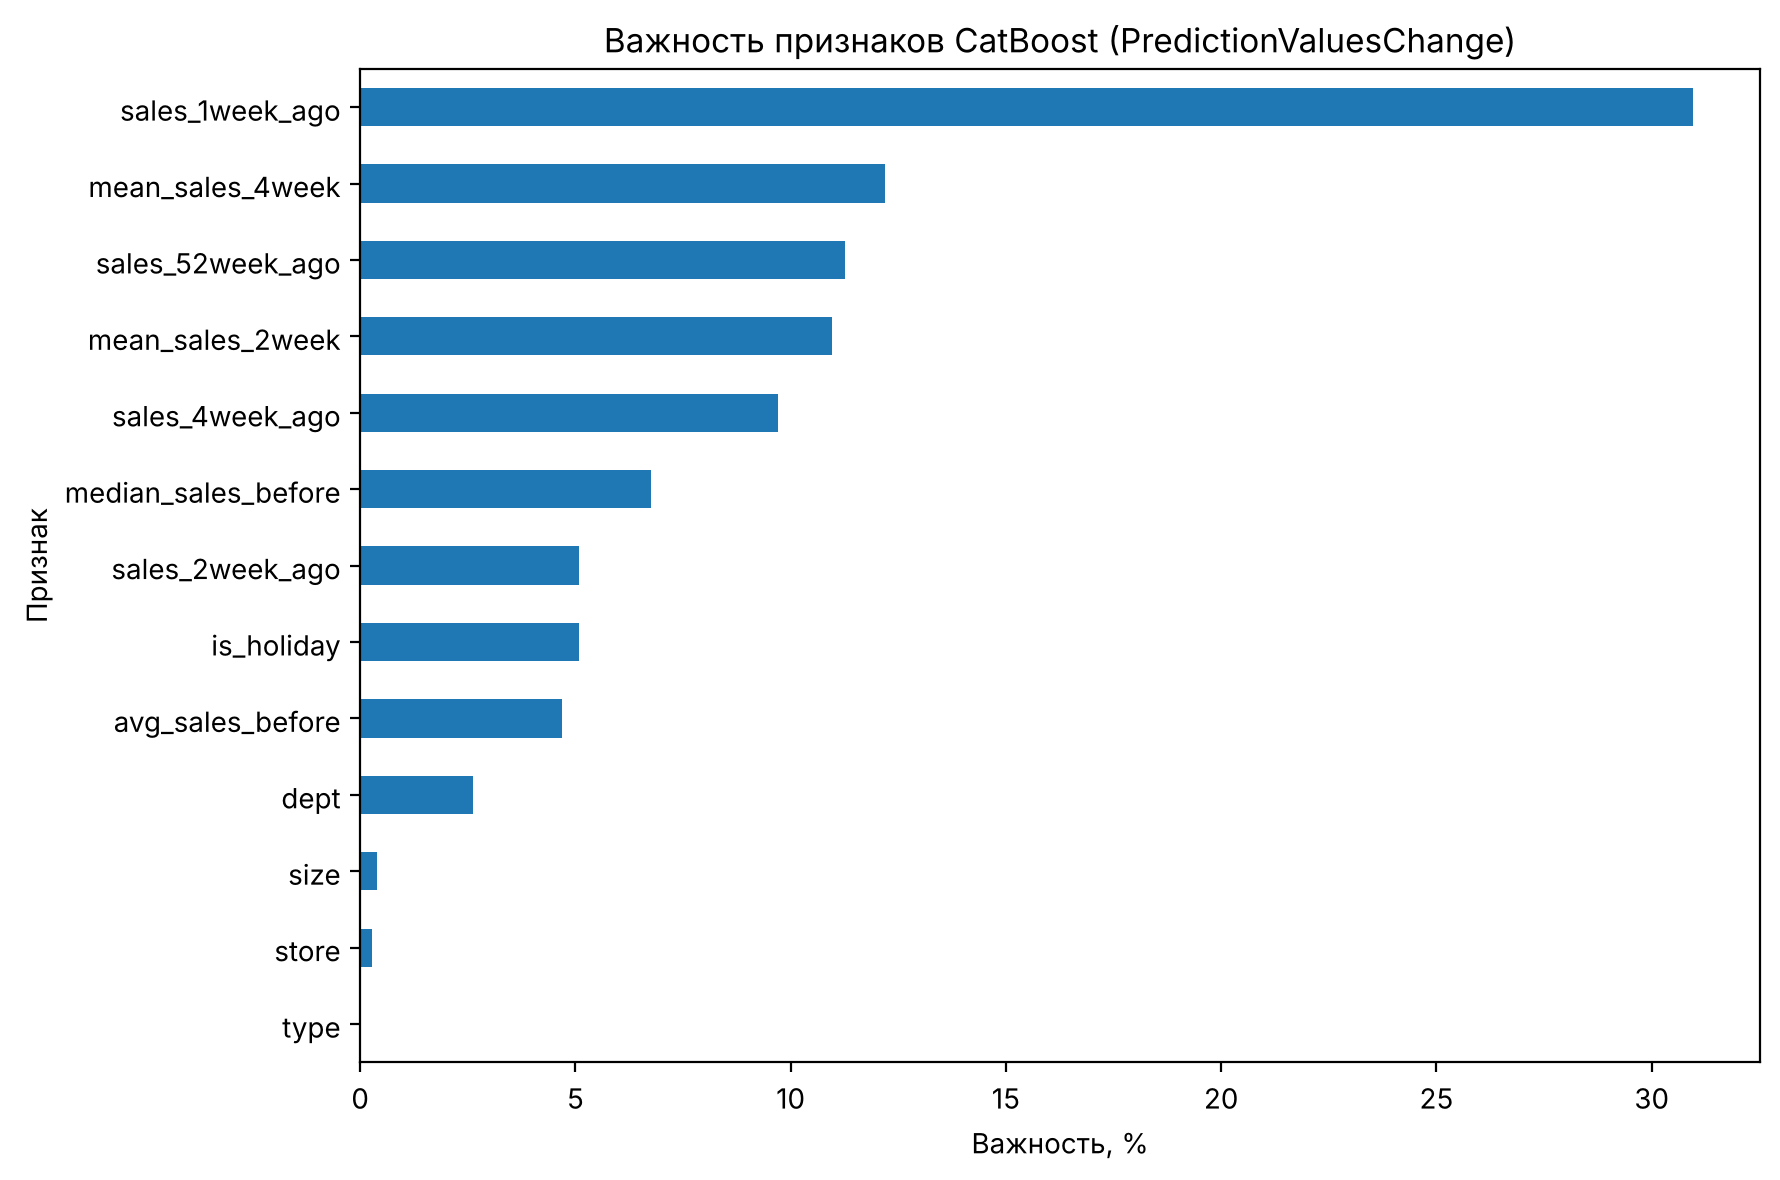

sales_1week_ago        30.97
mean_sales_4week       12.19
sales_52week_ago       11.25
mean_sales_2week       10.95
sales_4week_ago         9.71
median_sales_before     6.76
sales_2week_ago         5.09
is_holiday              5.08
avg_sales_before        4.69
dept                    2.62
size                    0.39
store                   0.28
type                    0.02
dtype: float64


In [33]:
importance = pd.Series(cb.get_feature_importance(), index=feature_cols).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
importance.plot.barh(ax=ax)
ax.set(title='Важность признаков CatBoost (PredictionValuesChange)',
       xlabel='Важность, %', ylabel='Признак')
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False).round(2))

**Вывод.** Основной вклад дают признаки истории продаж: продажи неделю назад (31%),
скользящее среднее за 4 недели (12%), продажи год назад (11%), среднее за 2 недели (11%),
лаг 4 недели (10%). Все они построены строго по данным до даты прогноза — утечки нет.
Характеристики даркстора (`store`, `size`, `type`) почти не используются:
их информация уже содержится в истории продаж пары «даркстор–отдел».

In [34]:
import io
import pickle
import boto3

# Выгрузка модели в S3 для DAG батч-инференса. Ключи — в .env.
if os.getenv('S3_BUCKET'):
    s3_client = boto3.client(
        's3',
        endpoint_url='https://storage.yandexcloud.net',
        aws_access_key_id=os.getenv('S3_ACCESS_KEY_ID'),
        aws_secret_access_key=os.getenv('S3_SECRET_KEY'),
        region_name='ru-central1',
    )
    filebuffer = io.BytesIO()
    pickle.dump(cb, filebuffer)
    filebuffer.seek(0)
    s3_client.upload_fileobj(Fileobj=filebuffer, Bucket=os.getenv('S3_BUCKET'), Key='catboost_model.pkl')
    print('Модель выгружена в S3: catboost_model.pkl')
else:
    print('S3_BUCKET не задан — выгрузка модели пропущена')

S3_BUCKET не задан — выгрузка модели пропущена
